# Actividad 6 · Evaluación de portafolios
**Eduardo Aburto Angulo · AL07182743 · Tecmilenio · Módulo 2 / Semana 7**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eduardoaburtoa/actividad6-evaluacion-portafolios/blob/main/fuentes/entrena.ipynb)

Evaluación retrospectiva: el test ya se examinó en Actividad 5. Clase positiva = noticia negativa. A/B **simulado**, no evidencia de rentabilidad. Ejecute en orden; CPU suficiente. Se conservan salidas reales. El entrenamiento tarda varios minutos y vuelve a generar resultados locales. Una noticia negativa no es una orden de inversión.

In [1]:
# Instalación previa a imports numéricos; en Colab se trabaja desde una copia del repo.
from pathlib import Path
import sys, subprocess, os, importlib.metadata as meta
if Path('fuentes/experimento.py').exists():
    ROOT=Path.cwd()
elif Path.cwd().name=='fuentes' and Path('experimento.py').exists():
    ROOT=Path.cwd().parent
else:
    ROOT=Path.cwd()/'Actividad6'
    if not (ROOT/'fuentes/experimento.py').exists():
        subprocess.run(['git','clone','https://github.com/eduardoaburtoa/actividad6-evaluacion-portafolios.git',str(ROOT)],check=True)
os.chdir(ROOT)
os.environ['MPLCONFIGDIR']=str(ROOT/'.cache-matplotlib')
sys.path.insert(0,str(ROOT))
required={line.split('==')[0]:line.split('==')[1] for line in (ROOT/'requirements.txt').read_text().splitlines() if '==' in line and not line.startswith('#')}
missing=[]
for package,version in required.items():
    try:
        if meta.version(package)!=version:missing.append(package)
    except meta.PackageNotFoundError:missing.append(package)
restart_needed=False
if missing:
    loaded=any(name in sys.modules for name in ['numpy','pandas','sklearn','scipy'])
    subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(ROOT/'requirements.txt')],check=True)
    restart_needed=loaded
print('Python:',sys.version.split()[0])
print({package:meta.version(package) for package in required})
print('Reinicia la sesión y vuelve a ejecutar desde aquí.' if restart_needed else 'Entorno listo; continúa en orden.')
if restart_needed:
    # Colab ofrece reconexión tras reiniciar; evita usar módulos binarios ya cargados.
    if 'google.colab' in sys.modules:
        from google.colab import runtime
        runtime.restart_runtime()
    else:
        print('En Jupyter, Kernel > Restart. No continúes con versiones mezcladas.')


Python: 3.12.14
{'numpy': '2.2.6', 'pandas': '2.2.3', 'scipy': '1.18.1', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.3', 'mlflow': '2.22.2', 'streamlit': '1.66.0', 'joblib': '1.6.0', 'SQLAlchemy': '2.0.40'}
Entorno listo; continúa en orden.


Las versiones se comprueban antes de importar las librerías. Si el entorno tenía versiones cargadas distintas, se requiere reinicio; en un entorno nuevo no hace falta.

In [2]:
# Configuración idéntica al experimento auditado.
import os,json,hashlib,time,platform,math
os.environ.setdefault('MPLBACKEND','Agg')
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold,cross_val_predict
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,roc_curve,average_precision_score
from scipy.stats import fisher_exact,binomtest,norm
import mlflow

from IPython.display import display, Image
__file__=str(ROOT/"fuentes/experimento.py")
SEED=20261022
GRID=np.round(np.arange(.05,.951,.025),3)
COST_FN=5
np.random.seed(SEED)
print("Semilla:",SEED)


Matplotlib is building the font cache; this may take a moment.


Semilla: 20261022


Conservo la semilla y los hiperparámetros originales; la ampliación no busca mejorar resultados cambiando la configuración.

In [3]:
# Conteos originales, limpieza y distribución de clases.
data=pd.read_csv(ROOT/'datos/datos_limp/phrasebank_v1.csv')
data['y']=(data.etiqueta=='negative').astype(int)
dev=data[data.split=='train'].reset_index(drop=True);test=data[data.split=='test'].reset_index(drop=True)
display(pd.DataFrame({'etapa':['Originales','Duplicados retirados','Limpios','Desarrollo','Test histórico'],'registros':[2264,2264-len(data),len(data),len(dev),len(test)]}))
display(pd.crosstab(data.split,data.etiqueta))
assert (len(data),len(dev),len(test))==(2259,1807,452)


,etapa,registros
0,Originales,2264
1,Duplicados retirados,5
2,Limpios,2259
3,Desarrollo,1807
4,Test histórico,452


etiqueta,negative,neutral,positive
split,,,
test,61,277,114
train,242,1109,456


Se mantienen 1,807 noticias de desarrollo y 452 del test histórico. Los personajes ficticios son contexto A/B, no datos de entrenamiento.

In [4]:
# Dos pipelines visibles: TF-IDF se ajusta dentro de cada fold.
def build(name):
    estimator=LogisticRegression(C=1,solver="liblinear",max_iter=3000,random_state=SEED) if name=='Logistica' else LinearSVC(C=1,dual='auto',max_iter=10000,random_state=SEED)
    pipe=make_pipeline(TfidfVectorizer(ngram_range=(1,2),sublinear_tf=True,max_features=25000),estimator)
    return pipe if name=='Logistica' else CalibratedClassifierCV(pipe,method='sigmoid',cv=StratifiedKFold(3,shuffle=True,random_state=SEED),n_jobs=1)

def measure(y,p,t):
    pred=(np.asarray(p)>=t).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {k:float(v) for k,v in dict(accuracy=accuracy_score(y,pred),precision=precision_score(y,pred,zero_division=0),recall=recall_score(y,pred,zero_division=0),f1=f1_score(y,pred,zero_division=0),auc=roc_auc_score(y,p),average_precision=average_precision_score(y,p),tn=tn,fp=fp,fn=fn,tp=tp,cost_per_100=100*(COST_FN*fn+fp)/len(y),review_rate=pred.mean()).items()}

def choose(y,p):
    rows=pd.DataFrame([dict(threshold=t,**measure(y,p,t)) for t in GRID])
    feasible=rows[(rows.recall>=.90)&(rows.precision>=.60)]
    pool=feasible if len(feasible) else rows
    winner=pool.sort_values(['cost_per_100','threshold'],ascending=[True,False]).iloc[0]
    return float(winner.threshold),bool(len(feasible)),rows

display(build("Logistica"))
display(build("SVM_calibrada"))

Pipeline(steps=[('tfidfvectorizer',
                 TfidfVectorizer(max_features=25000, ngram_range=(1, 2),
                                 sublinear_tf=True)),
                ('logisticregression',
                 LogisticRegression(C=1, max_iter=3000, random_state=20261022,
                                    solver='liblinear'))])

CalibratedClassifierCV(cv=StratifiedKFold(n_splits=3, random_state=20261022, shuffle=True),
                       estimator=Pipeline(steps=[('tfidfvectorizer',
                                                  TfidfVectorizer(max_features=25000,
                                                                  ngram_range=(1,
                                                                               2),
                                                                  sublinear_tf=True)),
                                                 ('linearsvc',
                                                  LinearSVC(C=1, max_iter=10000,
                                                            random_state=20261022))]),
                       n_jobs=1)

La calibración sigmoide contiene el pipeline completo. El costo 5FN+FP es didáctico y no equivale a pesos.

In [5]:
# Código de la asignación y resultados A/B simulados.
def wilson(k,n):
    z=norm.ppf(.9875);p=k/n;d=1+z*z/n
    c=(p+z*z/(2*n))/d;h=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return float(c-h),float(c+h)

def ab_simulation(out):
    # Independent RNGs: assignment cannot change potential outcome generation.
    clients=pd.read_csv(ROOT/'contexto/clientes_simulados.csv')
    rng=np.random.default_rng(SEED);assigned=[]
    extra=0
    for _,group in clients.groupby('perfil_riesgo',sort=True):
        ids=rng.permutation(group.index)
        n_a=len(ids)//2+(len(ids)%2 and extra%2==0)
        if len(ids)%2:extra+=1
        assigned.extend((int(i),'A' if j<n_a else 'B') for j,i in enumerate(ids))
    arm=dict(assigned);sim=clients[['cliente_id','nombre','perfil_riesgo','posicion_mxn']].copy()
    sim['grupo']=[arm[i] for i in sim.index]
    rng=np.random.default_rng(SEED+1)
    sim['exito_revision_simulado']=(rng.random(len(sim))<np.where(sim.grupo=='A',.72,.85)).astype(int)
    sim['origen']='SIMULADO; no observaciones de clientes ni impacto financiero real'
    sim.to_csv(out/'ab_simulado.csv',index=False)
    a=sim[sim.grupo=='A'].exito_revision_simulado;b=sim[sim.grupo=='B'].exito_revision_simulado
    pa,pb=a.mean(),b.mean();la,ua=wilson(a.sum(),len(a));lb,ub=wilson(b.sum(),len(b))
    delta=pb-pa;ci=[lb-ua,ub-la]
    p=fisher_exact([[a.sum(),len(a)-a.sum()],[b.sum(),len(b)-b.sum()]]).pvalue
    p1,p2=.72,.85;avg=(p1+p2)/2
    n=math.ceil(((norm.ppf(.975)*np.sqrt(2*avg*(1-avg))+norm.ppf(.8)*np.sqrt(p1*(1-p1)+p2*(1-p2)))**2)/(p2-p1)**2)
    return dict(type='SIMULACION DIDACTICA',unit='cliente ficticio; una revisión por cliente',primary='proporción de revisiones completas en 48 h',hypotheses='H0: pB=pA; H1: pB!=pA',assumed_pA=p1,assumed_pB=p2,nA=len(a),nB=len(b),successA=int(a.sum()),successB=int(b.sum()),rateA=pa,rateB=pb,delta=delta,ci95_wilson_bonferroni_approx=ci,fisher_exact_p=p,alpha=.05,power_target=.8,approx_n_per_arm=n,n_with_10pct_loss=math.ceil(n/.9),interpretation='Demuestra el procedimiento, no prueba efecto causal real. El diseño final requiere evaluar contaminación entre asesores y efecto de agrupación.')

print("A/B: 150 personajes; probabilidades supuestas 0.72 y 0.85.")

A/B: 150 personajes; probabilidades supuestas 0.72 y 0.85.


El código separa la asignación y la generación del resultado simulado. No representa observaciones de clientes.

## Validación cruzada anidada y entrenamiento

In [6]:
# Cinco folds externos y tres internos para umbral; código original visible.
out=ROOT/'resultados';out.mkdir(exist_ok=True)
data=pd.read_csv(ROOT/'datos/datos_limp/phrasebank_v1.csv')
data['y']=(data.etiqueta=='negative').astype(int)
dev=data[data.split=='train'].reset_index(drop=True);test=data[data.split=='test'].reset_index(drop=True)
X=dev.texto;y=dev.y;yt=test.y.to_numpy()
# Every run uses a separate local store; original results can be preserved by copying the repo.
mlflow.set_tracking_uri(f'sqlite:///{ROOT / "mlflow.db"}')
exp='Actividad6_Evaluacion_'+str(SEED)
# Reuse the store safely after moving the repository.
import sqlite3
if (ROOT/'mlflow.db').exists():
    with sqlite3.connect(ROOT/'mlflow.db') as db:
        if db.execute("select name from sqlite_master where name='experiments'").fetchone():
            db.execute('update experiments set artifact_location=? where name=?',((ROOT/'mlartifacts').as_uri(),exp))
if mlflow.get_experiment_by_name(exp) is None:mlflow.create_experiment(exp,artifact_location=(ROOT/'mlartifacts').as_uri())
mlflow.set_experiment(exp)
folds=list(StratifiedKFold(5,shuffle=True,random_state=SEED).split(X,y))
metrics=[];cvrows=[];thresholds={};probs={};oofall=[];runs=[]
for name in ['Logistica','SVM_calibrada']:
    with mlflow.start_run(run_name=name) as run:
        start=time.perf_counter()
        for fold,(tr,va) in enumerate(folds):
            inner=StratifiedKFold(3,shuffle=True,random_state=SEED+fold)
            ptr=cross_val_predict(build(name),X.iloc[tr],y.iloc[tr],cv=inner,method='predict_proba',n_jobs=1)[:,1]
            t,feasible,_=choose(y.iloc[tr],ptr)
            m=build(name).fit(X.iloc[tr],y.iloc[tr]);pv=m.predict_proba(X.iloc[va])[:,1]
            cvrows.append(dict(model=name,fold=fold,threshold=t,feasible_inner=feasible,**measure(y.iloc[va],pv,t)))
            oofall.extend(dict(model=name,id=dev.iloc[j].id,fold=fold,y=int(y.iloc[j]),score=float(p),threshold=t) for j,p in zip(va,pv))
        # Fit final threshold only on development OOF predictions; no test target used.
        oof=cross_val_predict(build(name),X,y,cv=folds,method='predict_proba',n_jobs=1)[:,1]
        t,feasible,grid=choose(y,oof);thresholds[name]=dict(threshold=t,feasible_dev=feasible)
        grid.to_csv(out/f'umbrales_{name}_desarrollo.csv',index=False)
        model=build(name).fit(X,y);pt=model.predict_proba(test.texto)[:,1];probs[name]=pt
        for label,cut in [('default',.5),('ajustado',t)]:metrics.append(dict(model=name,policy=label,threshold=cut,**measure(yt,pt,cut)))
        mlflow.log_params(dict(seed=SEED,positive='negative',C=1,ngram='1,2',outer_folds=5,inner_threshold_folds=3,solver='liblinear' if name=='Logistica' else 'liblinear SVC',calibration='sigmoid 3 folds' if name!='Logistica' else 'none',threshold=t,cost_fn=COST_FN,cost_fp=1,source_commit='ffcab30094541ebbe7f52f1c55062068d59e1e4f',data_sha256=hashlib.sha256((ROOT/'datos/datos_limp/phrasebank_v1.csv').read_bytes()).hexdigest(),code_sha256=hashlib.sha256(Path(__file__).read_bytes()).hexdigest()))
        mlflow.log_metrics({**measure(yt,pt,t),'fit_seconds':time.perf_counter()-start})
        mlflow.log_artifact(str(out/f'umbrales_{name}_desarrollo.csv'))
        # Compact model for reproducible inference, own trusted artifact only.
        import joblib
        joblib.dump(model,out/f'modelo_{name}.joblib',compress=3)
        mlflow.log_artifact(str(out/f'modelo_{name}.joblib'))
        runs.append(dict(model=name,run_id=run.info.run_id))

display(pd.DataFrame(cvrows)[["model","fold","threshold","precision","recall","f1","auc","cost_per_100"]])

2026/10/23 19:31:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/23 19:31:51 INFO mlflow.store.db.utils: Updating database tables


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step


...

INFO  [alembic.runtime.migration] Running upgrade 4465047574b1 -> f5a4f2784254, increase run tag value limit to 8000


INFO  [alembic.runtime.migration] Running upgrade f5a4f2784254 -> 0584bdc529eb, add cascading deletion to datasets from experiments


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


,model,fold,threshold,precision,recall,f1,auc,cost_per_100
0,Logistica,0,0.175,0.436620,0.632653,0.516667,0.860990,35.911602
1,Logistica,1,0.150,0.426966,0.775510,0.550725,0.903241,29.281768
2,Logistica,2,0.150,0.494118,0.875000,0.631579,0.952276,20.221607
3,Logistica,3,0.125,0.437500,0.875000,0.583333,0.912540,23.268698
4,Logistica,4,0.150,0.437500,0.875000,0.583333,0.935037,23.268698
5,SVM_calibrada,0,0.200,0.654545,0.734694,0.692308,0.896981,23.204420
6,SVM_calibrada,1,0.150,0.569444,0.836735,0.677686,0.937276,19.613260
7,SVM_calibrada,2,0.225,0.714286,0.833333,0.769231,0.972710,15.512465
8,SVM_calibrada,3,0.150,0.571429,0.833333,0.677966,0.936701,19.390582
9,SVM_calibrada,4,0.250,0.728814,0.895833,0.803738,0.972045,11.357341


Cada fold externo se evalúa sin usar sus etiquetas para elegir el umbral. Los folds comparten datos de entrenamiento y no son muestras independientes para una prueba t.

In [7]:
# Consolidación de CV, test, bootstrap y A/B con las semillas originales.
cv=pd.DataFrame(cvrows);cv.to_csv(out/'validacion_cruzada.csv',index=False)
pd.DataFrame(oofall).to_csv(out/'predicciones_cv.csv',index=False)
summary=cv.groupby('model')[['accuracy','precision','recall','f1','auc','cost_per_100']].agg(['mean','std'])
summary.to_csv(out/'resumen_cv.csv')
selected=cv.groupby('model').cost_per_100.mean().sort_values().index[0]
for name,p,t in [('Dummy_mayoria',np.full(len(yt),y.mean()),.5),('Revisar_todas',np.ones(len(yt)),.5)]:metrics.append(dict(model=name,policy='baseline',threshold=t,**measure(yt,p,t)))
pd.DataFrame(metrics).to_csv(out/'metricas_test.csv',index=False)
pred=test[['id','texto','etiqueta','y']].copy()
for name,p in probs.items():pred[name]=p
pred.to_csv(out/'predicciones_test.csv',index=False)
p=probs[selected];t=thresholds[selected]['threshold'];pp=(p>=t).astype(int);default=(p>=.5).astype(int)
rng=np.random.default_rng(SEED);boot=[]
for _ in range(2000):
    idx=np.concatenate([rng.choice(np.where(yt==k)[0],sum(yt==k),replace=True) for k in [0,1]])
    boot.append([roc_auc_score(yt[idx],p[idx]),f1_score(yt[idx],pp[idx]),recall_score(yt[idx],pp[idx])-recall_score(yt[idx],default[idx])])
lo,hi=np.quantile(boot,[.025,.975],axis=0)
b=int(((default==yt)&(pp!=yt)).sum());c=int(((default!=yt)&(pp==yt)).sum())
stats=dict(selected_by_nested_cv_cost=selected,thresholds=thresholds,bootstrap_repeats=2000,auc_ci95=[lo[0],hi[0]],f1_ci95=[lo[1],hi[1]],delta_recall_ci95=[lo[2],hi[2]],mcnemar_discordant=[b,c],mcnemar_exact_p=float(binomtest(b,b+c,.5).pvalue) if b+c else 1,warning='Test histórico ya examinado en Actividad5; evaluación retrospectiva. IC condicionales al test, no prueba externa prospectiva.')
ab=ab_simulation(out)
(out/'estadistica.json').write_text(json.dumps(stats,indent=2,ensure_ascii=False))
(out/'ab_analisis.json').write_text(json.dumps(ab,indent=2,ensure_ascii=False))
(out/'entorno.json').write_text(json.dumps(dict(python=platform.python_version(),platform=platform.platform(),seed=SEED,mlflow=mlflow.__version__,runs=runs),indent=2))

display(pd.DataFrame(metrics))
print(json.dumps(stats,indent=2))

,model,policy,threshold,accuracy,precision,recall,f1,auc,average_precision,tn,fp,fn,tp,cost_per_100,review_rate
0,Logistica,default,0.500,0.900442,0.944444,0.278689,0.430380,0.922896,0.732949,390.0,1.0,44.0,17.0,48.893805,0.039823
1,Logistica,ajustado,0.125,0.805310,0.396947,0.852459,0.541667,0.922896,0.732949,312.0,79.0,9.0,52.0,27.433628,0.289823
2,SVM_calibrada,default,0.500,0.938053,0.851064,0.655738,0.740741,0.954761,0.846829,384.0,7.0,21.0,40.0,24.778761,0.103982
3,SVM_calibrada,ajustado,0.200,0.922566,0.671053,0.836066,0.744526,0.954761,0.846829,366.0,25.0,10.0,51.0,16.592920,0.168142
4,Dummy_mayoria,baseline,0.500,0.865044,0.000000,0.000000,0.000000,0.500000,0.134956,391.0,0.0,61.0,0.0,67.477876,0.000000
5,Revisar_todas,baseline,0.500,0.134956,0.134956,1.000000,0.237817,0.500000,0.134956,0.0,391.0,0.0,61.0,86.504425,1.000000


{
  "selected_by_nested_cv_cost": "SVM_calibrada",
  "thresholds": {
    "Logistica": {
      "threshold": 0.125,
      "feasible_dev": false
    },
    "SVM_calibrada": {
      "threshold": 0.2,
      "feasible_dev": false
    }
  },
  "bootstrap_repeats": 2000,
  "auc_ci95": [
    0.9284296255922183,
    0.9761435579220997
  ],
  "f1_ci95": [
    0.6715328467153284,
    0.8120300751879699
  ],
  "delta_recall_ci95": [
    0.08196721311475408,
    0.2786885245901639
  ],
  "mcnemar_discordant": [
    18,
    11
  ],
  "mcnemar_exact_p": 0.26493089646101,
  "warning": "Test hist\u00f3rico ya examinado en Actividad5; evaluaci\u00f3n retrospectiva. IC condicionales al test, no prueba externa prospectiva."
}


La política se elige en desarrollo; la meta conjunta no se cumple. El test es retrospectivo y los intervalos condicionan al corpus y a los modelos ya ajustados.

In [8]:
# Registro real de artefactos y generación de figuras del experimento.
# Scientific figures, blue BBVA palette.
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
fig,ax=plt.subplots(figsize=(7,4))
for name,score in probs.items():
    fpr,tpr,_=roc_curve(yt,score);ax.plot(fpr,tpr,label=f'{name} · AUC {roc_auc_score(yt,score):.3f}')
    pd.DataFrame(dict(fpr=fpr,tpr=tpr)).to_csv(out/f'roc_{name}.csv',index=False)
ax.plot([0,1],[0,1],'--',color='gray',label='Azar · AUC 0.50');ax.set(xlabel='Tasa de falsos positivos',ylabel='Recall de noticias negativas',title='ROC · test histórico');ax.legend();fig.tight_layout();fig.savefig(out/'roc.png',dpi=160);plt.close(fig)
fig,axs=plt.subplots(1,2,figsize=(9,3.5))
for ax,cut,label in zip(axs,[.5,t],['Umbral 0.50',f'Umbral {t:.3f}']):
    cm=confusion_matrix(yt,p>=cut);ax.imshow(cm,cmap='Blues')
    for i in range(2):
        for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else '#002E5D',fontsize=17)
    ax.set(xticks=[0,1],xticklabels=['No alerta','Alerta'],yticks=[0,1],yticklabels=['No negativa','Negativa'],xlabel='Predicción',ylabel='Real',title=label)
fig.suptitle(selected+' · clase positiva = noticia negativa');fig.tight_layout();fig.savefig(out/'confusion.png',dpi=160);plt.close(fig)
grid=pd.read_csv(out/f'umbrales_{selected}_desarrollo.csv');fig,ax=plt.subplots(figsize=(7,3.5))
for col in ['precision','recall','f1']:ax.plot(grid.threshold,grid[col],label=col)
ax.axvline(t,color='#004481',linestyle='--',label=f'elegido {t:.3f}');ax.set(xlabel='Umbral',ylabel='Métrica OOF',title='Ajuste en desarrollo · no se optimiza en test');ax.legend();fig.tight_layout();fig.savefig(out/'umbral.png',dpi=160);plt.close(fig)
fig,ax=plt.subplots(figsize=(7,3.5));m=pd.DataFrame(metrics);m['label']=m.model+' '+m.policy
m.set_index('label')[['recall','precision','f1']].plot.barh(ax=ax,color=['#004481','#1464A5','#49A5E6']);ax.set(xlim=(0,1),ylabel='',title='Test histórico · comparación con baselines');fig.tight_layout();fig.savefig(out/'comparacion.png',dpi=160);plt.close(fig)
fig,ax=plt.subplots(figsize=(6,3));ax.bar(['A · manual','B · asistida'],[ab['rateA'],ab['rateB']],color=['#004481','#49A5E6']);ax.set(ylim=(0,1),ylabel='Revisiones completas / total',title='A/B SIMULADO · sin clientes reales');fig.tight_layout();fig.savefig(out/'ab.png',dpi=160);plt.close(fig)
with mlflow.start_run(run_name='Validacion_y_AB_SIMULADO'):
    mlflow.log_params(dict(selected=selected,ab='SIMULADO',ab_seed=SEED,threshold=t));mlflow.log_metrics(dict(ab_fisher_p=ab['fisher_exact_p'],mcnemar_p=stats['mcnemar_exact_p']))
    for path in out.iterdir():
        if path.suffix in ['.json','.csv','.png']:mlflow.log_artifact(str(path))
print(json.dumps(stats,indent=2));print(pd.DataFrame(metrics).to_string(index=False));print(json.dumps(ab,indent=2))

{
  "selected_by_nested_cv_cost": "SVM_calibrada",
  "thresholds": {
    "Logistica": {
      "threshold": 0.125,
      "feasible_dev": false
    },
    "SVM_calibrada": {
      "threshold": 0.2,
      "feasible_dev": false
    }
  },
  "bootstrap_repeats": 2000,
  "auc_ci95": [
    0.9284296255922183,
    0.9761435579220997
  ],
  "f1_ci95": [
    0.6715328467153284,
    0.8120300751879699
  ],
  "delta_recall_ci95": [
    0.08196721311475408,
    0.2786885245901639
  ],
  "mcnemar_discordant": [
    18,
    11
  ],
  "mcnemar_exact_p": 0.26493089646101,
  "warning": "Test hist\u00f3rico ya examinado en Actividad5; evaluaci\u00f3n retrospectiva. IC condicionales al test, no prueba externa prospectiva."
}
        model   policy  threshold  accuracy  precision   recall       f1      auc  average_precision    tn    fp   fn   tp  cost_per_100  review_rate
    Logistica  default      0.500  0.900442   0.944444 0.278689 0.430380 0.922896           0.732949 390.0   1.0 44.0 17.0     48.89380

Las corridas registran métricas y artefactos reales. Los IDs de esta ejecución pueden diferir de los de la entrega original, pero se conservan hashes del código original y del dataset.

## Escenarios y ajuste de umbral

{
  "scope": "Exploratorio; test retrospectivo; sin ajuste por multiplicidad ni incertidumbre de reentrenamiento",
  "seed": 20261022,
  "bootstrap_repeats": 2000,
  "delta_auc": 0.03186449205484032,
  "delta_auc_ci95": [
    0.02062492138694384,
    0.045116556957779476
  ],
  "bootstrap_two_sided_tail_plus1": 0.0009995002498750624,
  "bootstrap_tail_interpretation": "Proporci\u00f3n de cola emp\u00edrica corregida; no p-valor de una distribuci\u00f3n nula centrada.",
  "mcnemar_models": {
    "svm_only_correct": 54,
    "logistic_only_correct": 1,
    "p": 3.1086244689504383e-15
  },
  "brier": {
    "SVM": 0.04625674670670211,
    "Logistica": 0.0740138789024259
  },
  "mean_probability_svm": 0.13653981420617786,
  "prevalence": 0.13495575221238937,
  "ab_design": {
    "method": "Aproximaci\u00f3n normal bilateral; pA=.72; n=75 por brazo; alpha=.05; no potencia exacta de Fisher",
    "power_assumed_delta_0_13": 0.49107804394614196,
    "mde_power_0_8": 0.17836245741334647
  }
}
 th

,threshold,accuracy,precision,recall,f1,auc,average_precision,tn,fp,fn,tp,cost_per_100,review_rate
0,0.050,0.7742,0.3666,0.9421,0.5278,0.9432,0.8489,1171.0,394.0,14.0,228.0,25.6779,0.3442
1,0.075,0.8367,0.4462,0.9091,0.5986,0.9432,0.8489,1292.0,273.0,22.0,220.0,21.1954,0.2728
2,0.100,0.8672,0.5023,0.8884,0.6418,0.9432,0.8489,1352.0,213.0,27.0,215.0,19.2584,0.2369
3,0.125,0.8854,0.5457,0.8636,0.6688,0.9432,0.8489,1391.0,174.0,33.0,209.0,18.7604,0.2120
4,0.150,0.9020,0.5942,0.8471,0.6985,0.9432,0.8489,1425.0,140.0,37.0,205.0,17.9856,0.1909
5,0.175,0.9115,0.6265,0.8388,0.7173,0.9432,0.8489,1444.0,121.0,39.0,203.0,17.4875,0.1793
6,0.200,0.9186,0.6547,0.8306,0.7322,0.9432,0.8489,1459.0,106.0,41.0,201.0,17.2108,0.1699
7,0.225,0.9247,0.6879,0.8017,0.7405,0.9432,0.8489,1477.0,88.0,48.0,194.0,18.1516,0.1561
8,0.250,0.9303,0.7164,0.7934,0.7529,0.9432,0.8489,1489.0,76.0,50.0,192.0,18.0410,0.1483
9,0.275,0.9314,0.7305,0.7727,0.7510,0.9432,0.8489,1496.0,69.0,55.0,187.0,19.0371,0.1417


,threshold,accuracy,precision,recall,f1,auc,average_precision,tn,fp,fn,tp,cost_per_100,review_rate,reviews
0,0.075,0.8341,0.4435,0.9016,0.5946,0.9548,0.8468,322.0,69.0,6.0,55.0,21.9027,0.2743,124
1,0.200,0.9226,0.6711,0.8361,0.7445,0.9548,0.8468,366.0,25.0,10.0,51.0,16.5929,0.1681,76
2,0.500,0.9381,0.8511,0.6557,0.7407,0.9548,0.8468,384.0,7.0,21.0,40.0,24.7788,0.1040,47


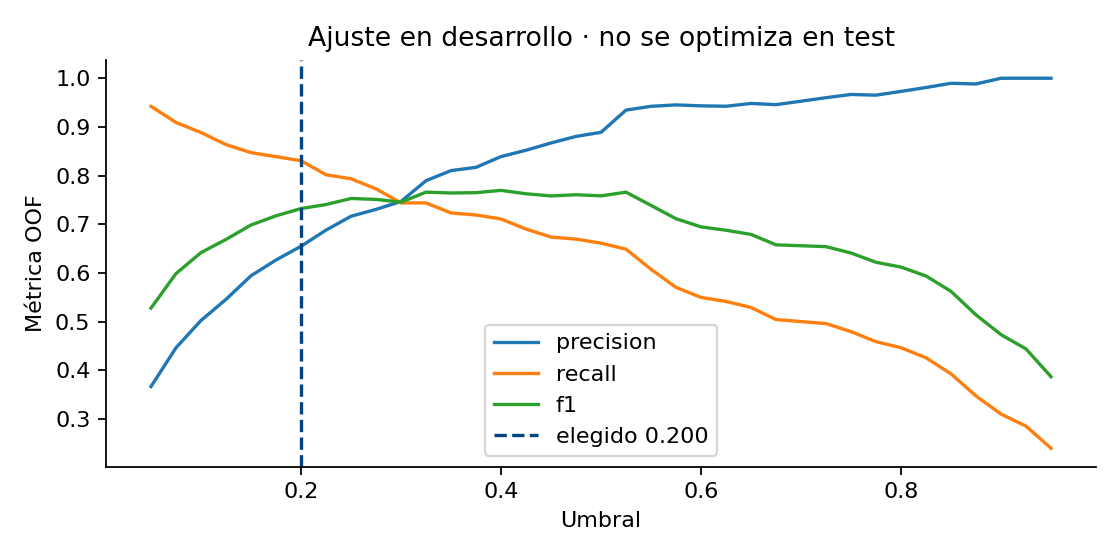

In [9]:
# Ampliación reproducible sin modificar el modelo ni elegir con test.
from fuentes.ampliacion import main as ampliar, power
ampliar()
display(pd.read_csv(ROOT/'resultados/umbrales_SVM_calibrada_desarrollo.csv').round(4))
display(pd.read_csv(ROOT/'resultados/escenarios_umbral.csv').round(4))
display(Image(filename=str(ROOT/'resultados/umbral.png')))


El umbral 0.075 supera recall 0.90 pero baja precisión a 0.4435 y eleva revisiones a 124. Mantengo 0.20; el escenario demuestra el intercambio, no una nueva selección.

## Matrices y métricas

Umbral
0.5
[[384   7]
 [ 21  40]]
Umbral
0.2
[[366  25]
 [ 10  51]]


,model,policy,threshold,accuracy,precision,recall,f1,auc,average_precision,tn,fp,fn,tp,cost_per_100,review_rate
0,Logistica,default,0.500,0.9004,0.9444,0.2787,0.4304,0.9229,0.7329,390.0,1.0,44.0,17.0,48.8938,0.0398
1,Logistica,ajustado,0.125,0.8053,0.3969,0.8525,0.5417,0.9229,0.7329,312.0,79.0,9.0,52.0,27.4336,0.2898
2,SVM_calibrada,default,0.500,0.9381,0.8511,0.6557,0.7407,0.9548,0.8468,384.0,7.0,21.0,40.0,24.7788,0.1040
3,SVM_calibrada,ajustado,0.200,0.9226,0.6711,0.8361,0.7445,0.9548,0.8468,366.0,25.0,10.0,51.0,16.5929,0.1681
4,Dummy_mayoria,baseline,0.500,0.8650,0.0000,0.0000,0.0000,0.5000,0.1350,391.0,0.0,61.0,0.0,67.4779,0.0000
5,Revisar_todas,baseline,0.500,0.1350,0.1350,1.0000,0.2378,0.5000,0.1350,0.0,391.0,0.0,61.0,86.5044,1.0000


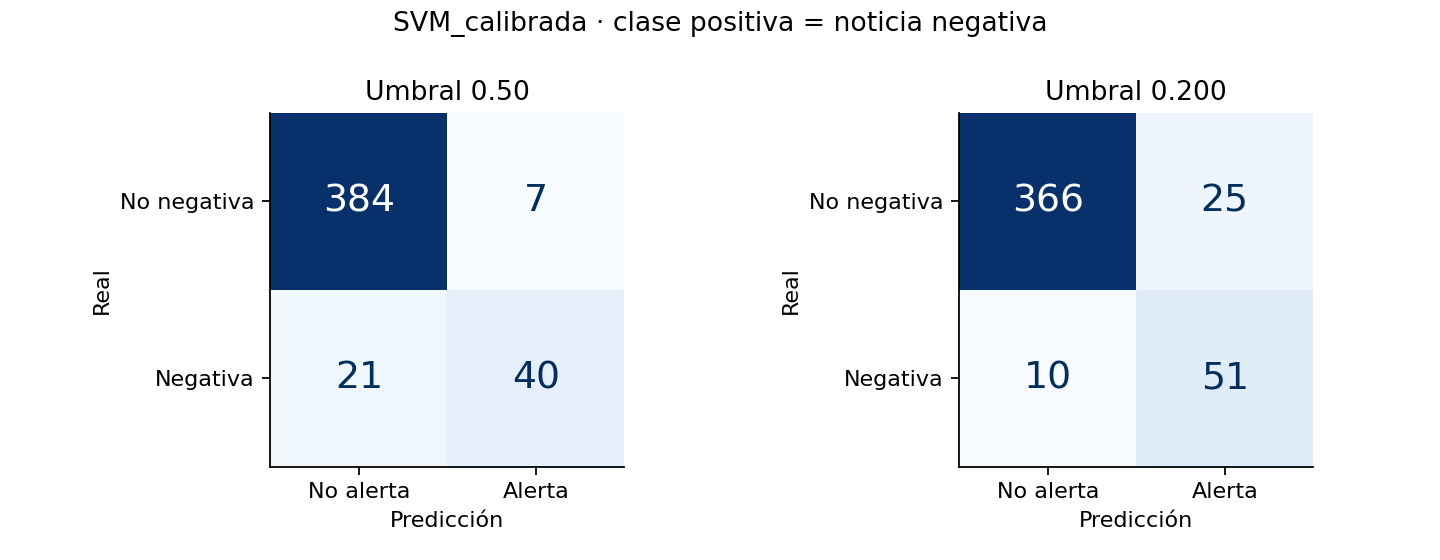

In [10]:
# Se verifican las dos matrices publicadas desde probabilidades.
for threshold in [.5,.2]:
    print('Umbral',threshold,confusion_matrix(yt,probs['SVM_calibrada']>=threshold),sep='\n')
display(pd.read_csv(ROOT/'resultados/metricas_test.csv').round(4))
display(Image(filename=str(ROOT/'resultados/confusion.png')))


Reducir el umbral disminuye FN de 21 a 10, pero aumenta FP de 7 a 25. Las métricas responden a cobertura y carga de trabajo, no prueban rendimiento financiero.

## ROC PR y fiabilidad

,modelo,Brier
0,SVM,0.046257
1,Logística,0.074014


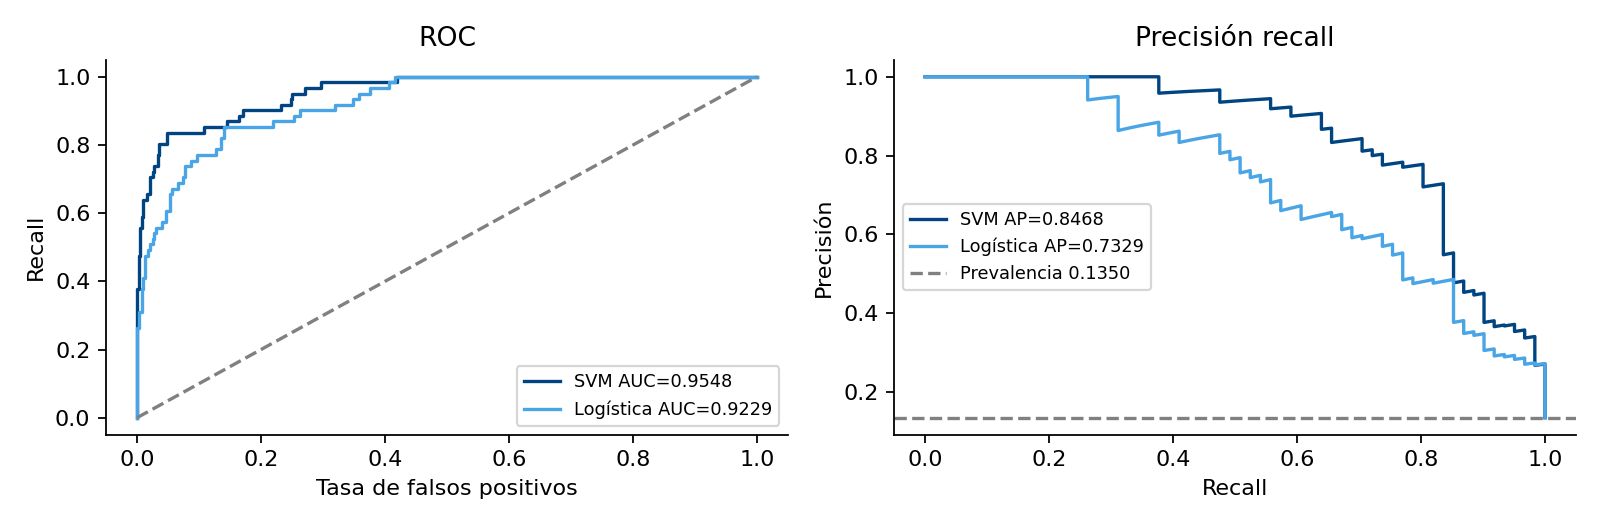

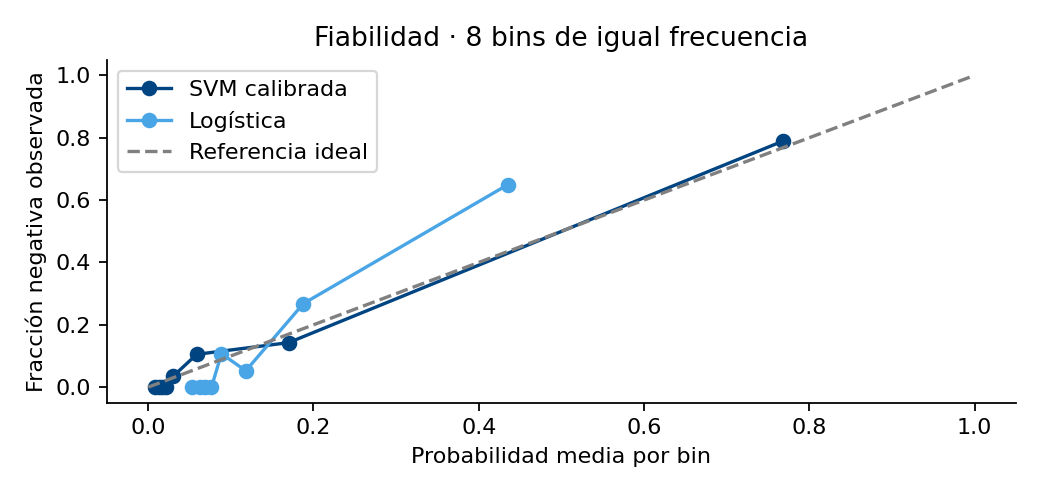

In [11]:
# Gráficas y Brier calculados con el mismo test histórico.
from sklearn.metrics import brier_score_loss
extra=json.loads((ROOT/'resultados/ampliacion.json').read_text())
display(pd.DataFrame({'modelo':['SVM','Logística'],'Brier':[brier_score_loss(yt,probs['SVM_calibrada']),brier_score_loss(yt,probs['Logistica'])]}))
for image_name in ['roc_pr.png','fiabilidad.png']:
    display(Image(filename=str(ROOT/'resultados'/image_name)))


La PR revela el costo de falsas alertas bajo desbalance. Brier menor y media predicha próxima a prevalencia apoyan la calidad probabilística, pero no demuestran calibración perfecta por segmento.

## Contrastes estadísticos

In [12]:
# Bootstrap pareado entre algoritmos y McNemar; código visible.
from scipy.optimize import brentq
out=ROOT/'resultados';d=pd.read_csv(out/'predicciones_test.csv')
y=d.y.to_numpy();s=d.SVM_calibrada.to_numpy();l=d.Logistica.to_numpy()
rng=np.random.default_rng(20261022);diff=[]
for _ in range(2000):
    idx=np.concatenate([rng.choice(np.flatnonzero(y==k),sum(y==k),replace=True) for k in [0,1]])
    diff.append(roc_auc_score(y[idx],s[idx])-roc_auc_score(y[idx],l[idx]))
ci=np.quantile(diff,[.025,.975]);a=((s>=.2)==y);b=((l>=.125)==y)
only_s=int((a&~b).sum());only_l=int((b&~a).sum())
# Cola empírica con corrección +1; no equivale a una prueba nula centrada.
tail=float(min(1,2*(min(sum(np.array(diff)<=0),sum(np.array(diff)>=0))+1)/2001))
result={'scope':'Exploratorio; test retrospectivo; sin ajuste por multiplicidad ni incertidumbre de reentrenamiento','seed':20261022,'bootstrap_repeats':2000,'delta_auc':float(roc_auc_score(y,s)-roc_auc_score(y,l)),'delta_auc_ci95':ci.tolist(),'bootstrap_two_sided_tail_plus1':tail,'bootstrap_tail_interpretation':'Proporción de cola empírica corregida; no p-valor de una distribución nula centrada.','mcnemar_models':{'svm_only_correct':only_s,'logistic_only_correct':only_l,'p':float(binomtest(only_s,only_s+only_l,.5).pvalue)},'brier':{'SVM':float(brier_score_loss(y,s)),'Logistica':float(brier_score_loss(y,l))},'mean_probability_svm':float(s.mean()),'prevalence':float(y.mean()),'ab_design':{'method':'Aproximación normal bilateral; pA=.72; n=75 por brazo; alpha=.05; no potencia exacta de Fisher','power_assumed_delta_0_13':power(.13),'mde_power_0_8':float(brentq(lambda delta:power(delta)-.8,.001,.279))}}

print(json.dumps(result,indent=2))
print("McNemar entre umbrales:",stats["mcnemar_exact_p"])

{
  "scope": "Exploratorio; test retrospectivo; sin ajuste por multiplicidad ni incertidumbre de reentrenamiento",
  "seed": 20261022,
  "bootstrap_repeats": 2000,
  "delta_auc": 0.03186449205484032,
  "delta_auc_ci95": [
    0.02062492138694384,
    0.045116556957779476
  ],
  "bootstrap_two_sided_tail_plus1": 0.0009995002498750624,
  "bootstrap_tail_interpretation": "Proporci\u00f3n de cola emp\u00edrica corregida; no p-valor de una distribuci\u00f3n nula centrada.",
  "mcnemar_models": {
    "svm_only_correct": 54,
    "logistic_only_correct": 1,
    "p": 3.1086244689504383e-15
  },
  "brier": {
    "SVM": 0.04625674670670211,
    "Logistica": 0.0740138789024259
  },
  "mean_probability_svm": 0.13653981420617786,
  "prevalence": 0.13495575221238937,
  "ab_design": {
    "method": "Aproximaci\u00f3n normal bilateral; pA=.72; n=75 por brazo; alpha=.05; no potencia exacta de Fisher",
    "power_assumed_delta_0_13": 0.49107804394614196,
    "mde_power_0_8": 0.17836245741334647
  }
}
McN

El IC de ΔAUC excluye cero. Son contrastes exploratorios sobre un test ya examinado: no sustituyen validación externa. La cola bootstrap corregida no se confunde con una prueba nula centrada.

## Potencia del A B simulado

{
  "type": "SIMULACION DIDACTICA",
  "unit": "cliente ficticio; una revisi\u00f3n por cliente",
  "primary": "proporci\u00f3n de revisiones completas en 48 h",
  "hypotheses": "H0: pB=pA; H1: pB!=pA",
  "assumed_pA": 0.72,
  "assumed_pB": 0.85,
  "nA": 75,
  "nB": 75,
  "successA": 48,
  "successB": 59,
  "rateA": 0.64,
  "rateB": 0.7866666666666666,
  "delta": 0.1466666666666666,
  "ci95_wilson_bonferroni_approx": [
    -0.08734018023202705,
    0.36225809597163217
  ],
  "fisher_exact_p": 0.07031708606068482,
  "alpha": 0.05,
  "power_target": 0.8,
  "approx_n_per_arm": 156,
  "n_with_10pct_loss": 174,
  "interpretation": "Demuestra el procedimiento, no prueba efecto causal real. El dise\u00f1o final requiere evaluar contaminaci\u00f3n entre asesores y efecto de agrupaci\u00f3n."
}
Potencia con 75 por brazo: 0.49107804394614196
MDE normal: 0.17836245741334647


,count,sum,mean
grupo,,,
A,75,48,0.640000
B,75,59,0.786667


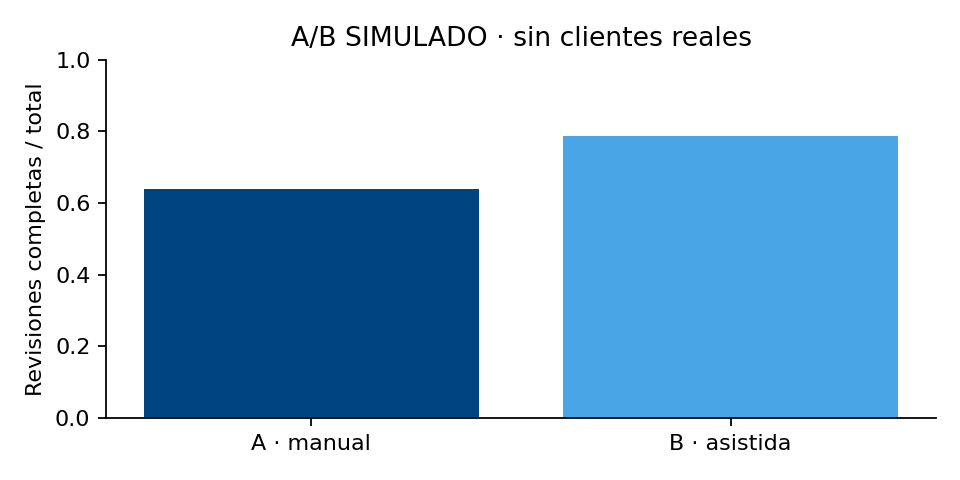

In [13]:
# Potencia aproximada bajo el efecto supuesto, no bajo el efecto observado.
def power(delta,n=75,p1=.72):
    # Aproximación normal bilateral con varianzas bajo H0 y H1.
    p2=p1+delta;bar=(p1+p2)/2
    crit=norm.ppf(.975)*np.sqrt(2*bar*(1-bar)/n)
    se=np.sqrt((p1*(1-p1)+p2*(1-p2))/n)
    return float(norm.sf((crit-delta)/se)+norm.cdf((-crit-delta)/se))
print(json.dumps(ab,indent=2))
print('Potencia con 75 por brazo:',power(.13))
print('MDE normal:',brentq(lambda delta:power(delta)-.8,.001,.279))
display(pd.read_csv(ROOT/'resultados/ab_simulado.csv').groupby('grupo').exito_revision_simulado.agg(['count','sum','mean']))
display(Image(filename=str(ROOT/'resultados/ab.png')))


Potencia aproximada 0.49 y MDE 17.84 puntos (17.9 al redondear hacia arriba). p=0.0703 no demuestra ausencia de efecto; tampoco se puede atribuir exclusivamente al tamaño de muestra. CV evalúa predicción; un A/B real evalúa intervención.

## Evidencia de MLflow

In [14]:
# Consulta real de las corridas de esta ejecución.
experiment=mlflow.get_experiment_by_name('Actividad6_Evaluacion_'+str(SEED))
runs_table=mlflow.search_runs(experiment_ids=[experiment.experiment_id])
columns=['run_id','status','tags.mlflow.runName','params.threshold','metrics.recall','metrics.f1','metrics.auc']
display(runs_table[[c for c in columns if c in runs_table]].fillna('—'))
assert (runs_table.status=='FINISHED').all()


,run_id,status,tags.mlflow.runName,params.threshold,metrics.recall,metrics.f1,metrics.auc
0,ee067b4c41244b2b8f0c7fbe8264ba0d,FINISHED,Validacion_y_AB_SIMULADO,0.2,—,—,—
1,26be2076b21c4e85ac30f3dace2689c2,FINISHED,SVM_calibrada,0.2,0.836066,0.744526,0.954761
2,241e6ec409034661928ad514b73d1cae,FINISHED,Logistica,0.125,0.852459,0.541667,0.922896


MLflow muestra las corridas completadas y sus métricas. El almacén de la entrega original continúa disponible por separado en evidencias/mlflow_bundle.zip.

## Decisión de negocio
Mantengo SVM calibrada 0.20 como candidata académica por menor costo medio de CV. La meta conjunta sigue pendiente. Necesito datos en español, licencia apropiada, evaluación temporal, capacidad operativa y revisión humana antes de cualquier piloto. El 1 % de compra más 1 % de venta es supuesto didáctico, no tarifa BBVA verificada. Los costos de error no son pesos. La IA no sustituye el criterio del banquero; lo aumenta.